# LASV proteome seroreactivity mapping

Unified workflow for mapping LASV PhIP-Seq peptide hits to the Josiah reference proteome and generating publication-ready seroreactivity plots for glycoprotein, nucleoprotein, polymerase, and Z protein.


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices

# ---------- paths ----------
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
REF_FASTA = Path('./ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta')
OUTDIR = Path('./output_figures')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- publication style ----------
plt.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})

CATEGORY_ORDER = ['Household contact', 'Lassa survivor', 'US healthy']
CATEGORY_COLORS = {
    'Household contact': '#0072B2',  # blue
    'Lassa survivor': '#D55E00',     # vermillion
    'US healthy': '#009E73',         # bluish green
}

## 1. Load LASV peptide-level data and Josiah references

In [17]:
pep_long = pd.read_csv(LONG_FILE)
lassa = pep_long.loc[pep_long['species'].eq('Mammarenavirus lassaense')].copy()

records = list(SeqIO.parse(REF_FASTA, 'fasta'))
reference_by_protein = {
    'polymerase': str(next(r.seq for r in records if 'O09705' in r.id)),
    'glycoprotein': str(next(r.seq for r in records if 'P08669' in r.id)),
    'nucleoprotein': str(next(r.seq for r in records if 'P13699' in r.id)),
    'z protein': str(next(r.seq for r in records if 'O73557' in r.id)),
}

print('LASV rows:', len(lassa))
print('LASV peptides:', lassa['peptide'].nunique())
for protein, seq in reference_by_protein.items():
    print(f'{protein:15s} {len(seq):4d} aa')


LASV rows: 119064
LASV peptides: 246
polymerase      2218 aa
glycoprotein     491 aa
nucleoprotein    569 aa
z protein         99 aa


## 2. Alignment and mapping functions

In [18]:
aligner = PairwiseAligner()
aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')
aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5


def map_peptide_to_reference(peptide, reference, aligner=aligner):
    """Map one peptide to a reference protein; coordinates are 1-based."""
    alignment = aligner.align(reference, peptide)[0]
    ref_blocks, pep_blocks = alignment.aligned

    ref_positions = []
    for (ref_start, ref_end), (pep_start, pep_end) in zip(ref_blocks, pep_blocks):
        ref_positions.extend(range(ref_start + 1, ref_end + 1))

    return {
        'score': alignment.score,
        'ref_start': ref_positions[0],
        'ref_end': ref_positions[-1],
        'ref_positions': ref_positions,
        'aligned_pep_length': sum(end - start for start, end in pep_blocks),
    }


def map_protein_peptides(protein_name):
    """Map all unique LASV peptide sequences for one standardized protein."""
    reference = reference_by_protein[protein_name]
    protein_df = lassa.loc[lassa['protein_std'].eq(protein_name)].copy()
    unique_sequences = protein_df['sequence'].dropna().drop_duplicates()

    mapping = []
    for sequence in unique_sequences:
        result = map_peptide_to_reference(sequence, reference)
        mapping.append({'sequence': sequence, **result})

    mapping_df = pd.DataFrame(mapping)
    protein_df = protein_df.merge(mapping_df, on='sequence', how='left', validate='many_to_one')
    return protein_df, mapping_df


## 3. Position-level seroreactivity
Each individual contributes at most once to a given amino-acid position, even when multiple reactive peptides overlap that position.

In [19]:
def summarize_position_reactivity(protein_name):
    protein_df, mapping_df = map_protein_peptides(protein_name)
    reference = reference_by_protein[protein_name]

    residues = (
        protein_df
        .explode('ref_positions')
        .rename(columns={'ref_positions': 'position'})
    )
    residues['position'] = pd.to_numeric(residues['position'], errors='coerce')

    reactive_residues = (
        residues.loc[residues['reactive'].fillna(False),
                     ['individual', 'cohort', 'category', 'position']]
        .dropna(subset=['position'])
        .drop_duplicates()
    )

    group_sizes = (
        protein_df[['individual', 'cohort', 'category']]
        .drop_duplicates()
        .groupby(['cohort', 'category'])
        .size()
        .rename('n_individuals')
        .reset_index()
    )

    position_counts = (
        reactive_residues
        .groupby(['cohort', 'category', 'position'])['individual']
        .nunique()
        .rename('n_seroreactive')
        .reset_index()
    )

    groups = protein_df[['cohort', 'category']].drop_duplicates()
    all_positions = pd.DataFrame({'position': np.arange(1, len(reference) + 1)})
    complete_grid = groups.merge(all_positions, how='cross')

    summary = complete_grid.merge(
        position_counts,
        on=['cohort', 'category', 'position'],
        how='left'
    )
    summary['n_seroreactive'] = summary['n_seroreactive'].fillna(0)
    summary = summary.merge(group_sizes, on=['cohort', 'category'], how='left')
    summary['pct_seroreactive'] = 100 * summary['n_seroreactive'] / summary['n_individuals']

    return summary, mapping_df, reactive_residues


## 5. Map all four LASV proteins once

In [20]:
position_summaries = {}
mapping_by_protein = {}
reactive_residues_by_protein = {}

for protein in ['glycoprotein', 'nucleoprotein', 'polymerase', 'z protein']:
    summary, mapping_df, reactive_residues = summarize_position_reactivity(protein)
    position_summaries[protein] = summary
    mapping_by_protein[protein] = mapping_df
    reactive_residues_by_protein[protein] = reactive_residues
    print(f'{protein:15s}: {mapping_df.shape[0]} unique mapped sequences')



glycoprotein   : 16 unique mapped sequences
nucleoprotein  : 29 unique mapped sequences
polymerase     : 193 unique mapped sequences
z protein      : 8 unique mapped sequences


## 5. Plotting function
Uses the `pct_seroreactive` column produced by `summarize_position_reactivity()`.


In [21]:
PROTEIN_LABELS = {
    "glycoprotein": "Glycoprotein",
    "nucleoprotein": "Nucleoprotein",
    "polymerase": "Polymerase",
    "z protein": "Z protein",
}

GPC_BOUNDARIES = [58, 259]

def plot_protein_seroreactivity(protein_name, ax=None, show_legend=True, ylim=(0, 100)):
    """Plot percent seroreactive individuals by Josiah amino-acid position."""
    summary = position_summaries[protein_name]
    reference = reference_by_protein[protein_name]

    if ax is None:
        _, ax = plt.subplots(figsize=(7.2, 3.3))

    for category in CATEGORY_ORDER:
        sub = (
            summary.loc[summary["category"].eq(category)]
            .sort_values("position")
        )
        if sub.empty:
            continue
        ax.plot(
            sub["position"],
            sub["pct_seroreactive"],
            lw=1.8,
            label=category,
            color=CATEGORY_COLORS[category],
        )

    if protein_name == "glycoprotein":
        for x in GPC_BOUNDARIES:
            ax.axvline(x, color="0.75", lw=0.8, ls=":", zorder=0)

    ax.set_xlim(1, len(reference))
    ax.set_ylim(*ylim)
    ax.set_xlabel(f"LASV {PROTEIN_LABELS[protein_name]} amino-acid position (Josiah)")
    ax.set_ylabel("Seroreactive individuals (%)")
    ax.set_title(f"{PROTEIN_LABELS[protein_name]} seroreactivity")

    if show_legend:
        ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.25))

    return ax


## 6. Individual protein figures


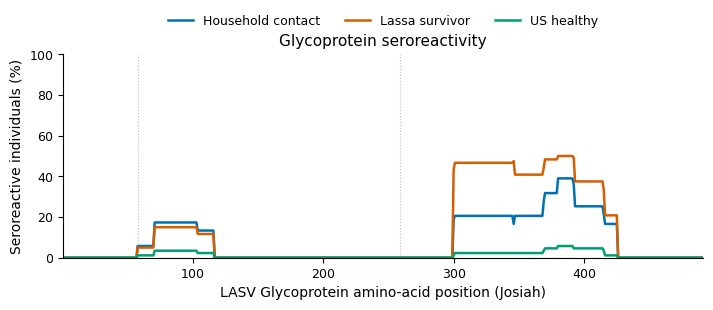

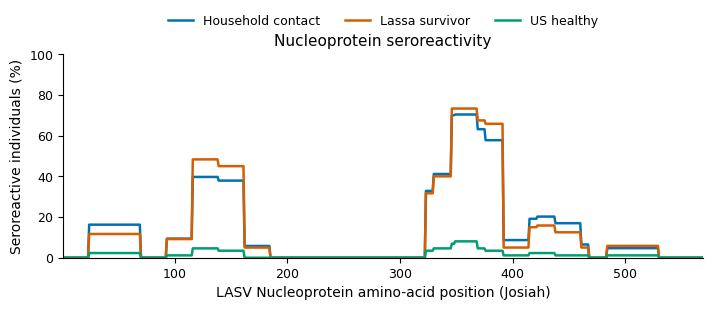

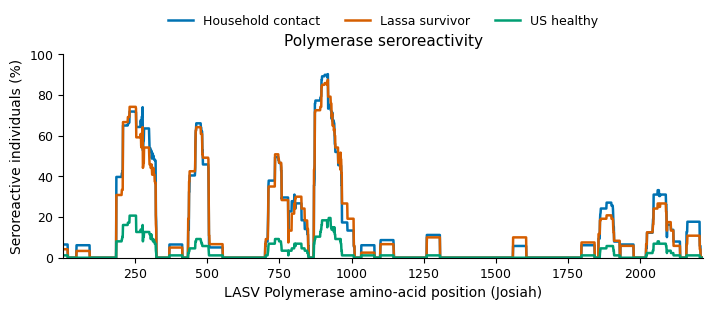

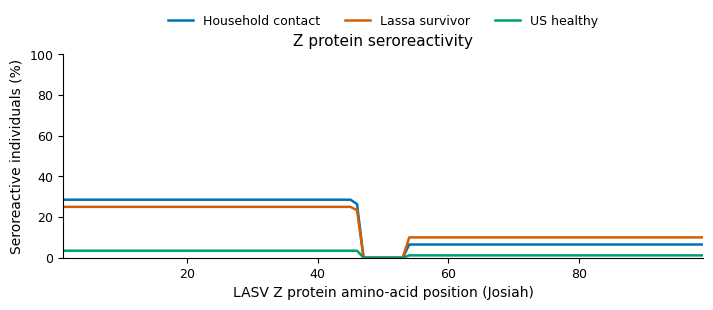

In [22]:
for protein in ['glycoprotein', 'nucleoprotein', 'polymerase', 'z protein']:
    fig, ax = plt.subplots(figsize=(7.2, 3.3))
    plot_protein_seroreactivity(
        protein,
        ax=ax,
        show_legend=True,
    )
    fig.tight_layout()
    stem = protein.replace(' ', '_')
    fig.savefig(OUTDIR / f'LASV_{stem}_seroreactivity.svg', bbox_inches='tight')
    fig.savefig(OUTDIR / f'LASV_{stem}_seroreactivity.pdf', bbox_inches='tight')
    plt.show()


## 7. Combined four-protein overview
Publication-ready overview with no survivor/contact discriminatory-region overlays.


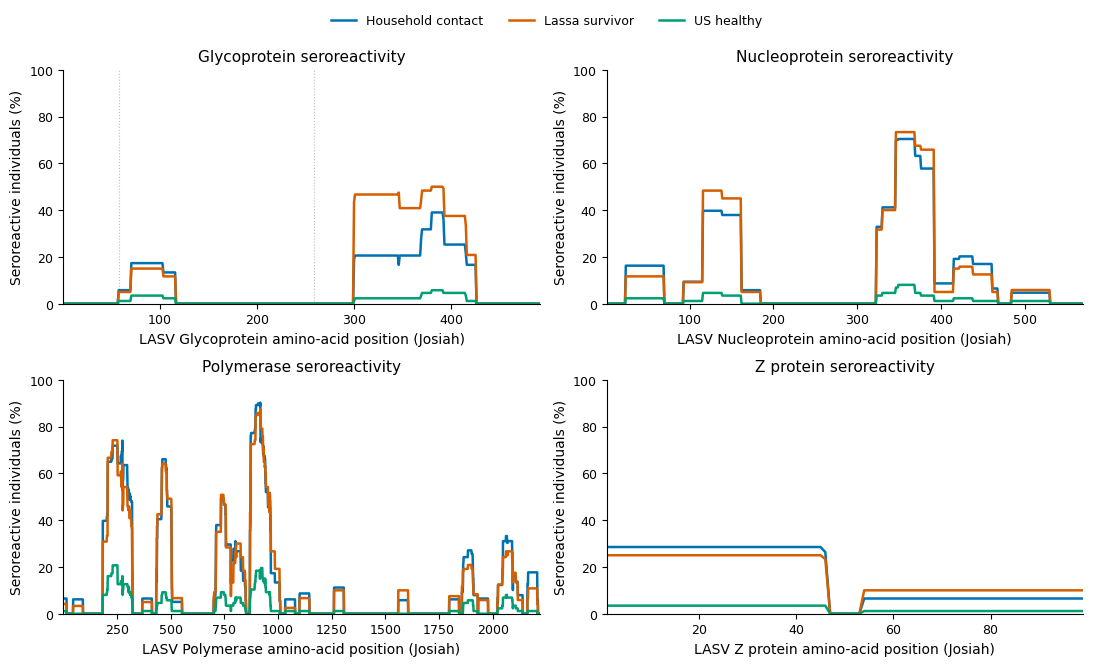

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
proteins = ['glycoprotein', 'nucleoprotein', 'polymerase', 'z protein']

for ax, protein in zip(axes.flat, proteins):
    plot_protein_seroreactivity(
        protein,
        ax=ax,
        show_legend=False,
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(OUTDIR / 'LASV_all_proteins_seroreactivity.svg', bbox_inches='tight')
fig.savefig(OUTDIR / 'LASV_all_proteins_seroreactivity.pdf', bbox_inches='tight')
plt.show()


## Combined 2 protein panel

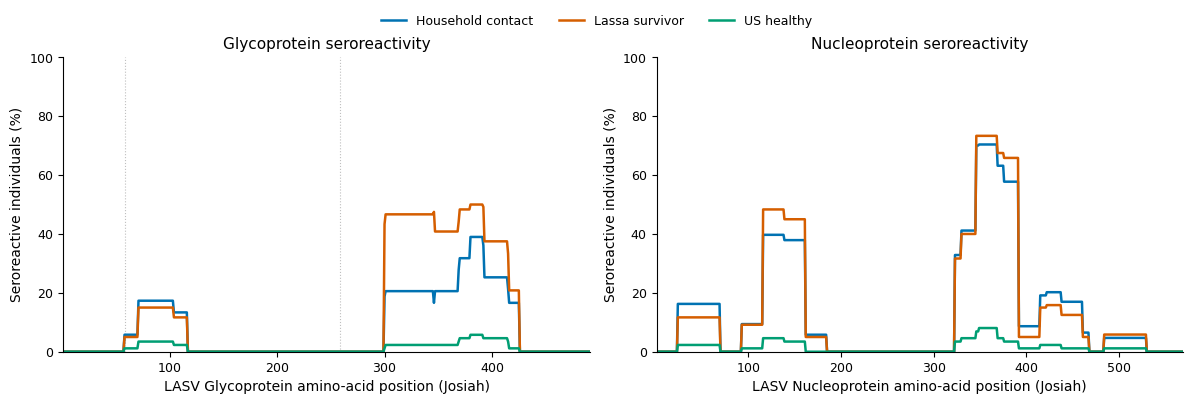

In [24]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4.0),
    constrained_layout=False
)

proteins = ['glycoprotein', 'nucleoprotein']

for ax, protein in zip(axes.flat, proteins):
    plot_protein_seroreactivity(
        protein,
        ax=ax,
        show_legend=False,
    )

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(OUTDIR / 'LASV_gp_and_np_proteins_seroreactivity.svg', bbox_inches='tight')
fig.savefig(OUTDIR / 'LASV_gp_and_np_seroreactivity.pdf', bbox_inches='tight')
plt.show()


## 8. Mapping QC
Inspect unusually short local alignments before publication.


In [25]:
mapping_qc = []
for protein, mapping_df in mapping_by_protein.items():
    tmp = mapping_df.copy()
    tmp['protein_std'] = protein
    tmp['peptide_length'] = tmp['sequence'].str.len()
    tmp['aligned_fraction'] = tmp['aligned_pep_length'] / tmp['peptide_length']
    mapping_qc.append(tmp)

mapping_qc = pd.concat(mapping_qc, ignore_index=True)
print(mapping_qc.groupby('protein_std')['aligned_fraction'].describe()[['count','mean','min']])

display(
    mapping_qc.sort_values('aligned_fraction')
    [['protein_std','sequence','ref_start','ref_end','aligned_pep_length','peptide_length','aligned_fraction']]
    .head(20)
)


               count      mean       min
protein_std                             
glycoprotein    16.0  1.000000  1.000000
nucleoprotein   29.0  0.997751  0.934783
polymerase     193.0  0.978486  0.347826
z protein        8.0  0.997283  0.978261


,protein_std,sequence,ref_start,ref_end,aligned_pep_length,peptide_length,aligned_fraction
96,polymerase,MVKFFDNNTNRVTHCTPPGRTPTQPPQLTMEEDIATAKDLISKYLA,1,16,16,46,0.347826
166,polymerase,NADLDEILLDGGASEYFDQLRCTVDNIVSQYKEQPERQQQADYNAP,896,927,32,46,0.695652
125,polymerase,LYTDEGIDNEDSIEQLSHQFKRVSPILRFLYADLEDKRPVGPAVDG,273,307,35,46,0.760870
112,polymerase,EMVSNEDGVEELMYSFKRASPVLKFLYADLTNGVDRSSPTNSSQMH,276,311,36,46,0.782609
202,polymerase,DVNRVDLDEVLLDGGASEYFDQLRCTVDNIVSQYRELPKKHQKVDC,892,927,36,46,0.782609
200,polymerase,KVDVCDDDVEHLEFQFKRASPVLKFLYANLDPSGDKTVNPQGEQMQ,279,314,36,46,0.782609
161,polymerase,LDEVLLDGGASMYFDQLRETVEKIVDQYKEPLRQNSHSITGDRASI,898,933,36,46,0.782609
71,polymerase,SKGGSCDTNNADLDEILLDGGASEYFDQLRCTVDNIVSQYREQPER,892,927,36,46,0.782609
80,polymerase,DEVNLDEILLEGGASIYFDELRETVEKIVDQYKEPLKHHSNSQDTA,894,930,37,46,0.804348
190,polymerase,KADLDEVLLEGDANIYFDQLRETIEKIVDQYREPTKSNSSFKDSSQ,896,933,38,46,0.826087
